<a href="https://colab.research.google.com/github/Arceus2006/AIML-project/blob/main/Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset shape: (2240, 29)
     ID  Year_Birth   Education Marital_Status   Income  Kidhome  Teenhome  \
0  5524        1957  Graduation         Single  58138.0        0         0   
1  2174        1954  Graduation         Single  46344.0        1         1   
2  4141        1965  Graduation       Together  71613.0        0         0   
3  6182        1984  Graduation       Together  26646.0        1         0   
4  5324        1981         PhD        Married  58293.0        1         0   

  Dt_Customer  Recency  MntWines  ...  NumWebVisitsMonth  AcceptedCmp3  \
0  04-09-2012       58       635  ...                  7             0   
1  08-03-2014       38        11  ...                  5             0   
2  21-08-2013       26       426  ...                  4             0   
3  10-02-2014       26        11  ...                  6             0   
4  19-01-2014       94       173  ...                  5             0   

   AcceptedCmp4  AcceptedCmp5  AcceptedCmp1  AcceptedCmp2  C

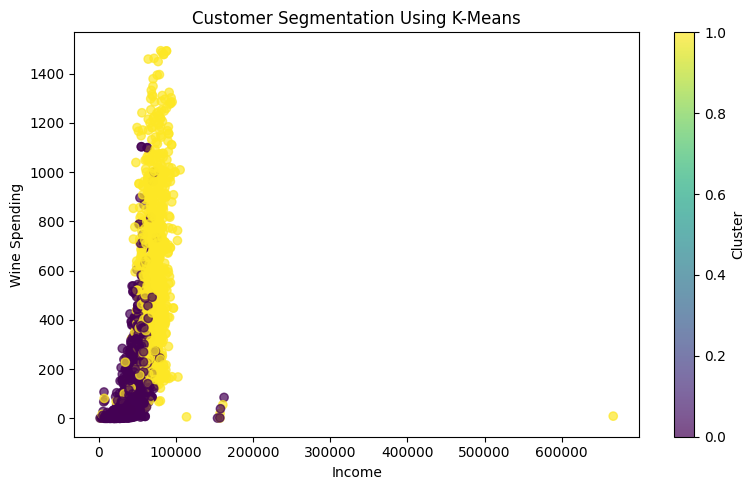


Clustered dataset saved successfully!


In [ ]:

# Step 1: Import libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Step 2: Load the dataset
df = pd.read_csv("customer_segmentation.csv")

print("Dataset shape:", df.shape)
print(df.head())

# Step 3: Select relevant numerical features
features = [
    "Year_Birth", "Income", "Kidhome", "Teenhome",
    "Recency", "MntWines", "MntFruits",
    "MntMeatProducts", "MntFishProducts",
    "MntSweetProducts", "MntGoldProds",
    "NumDealsPurchases", "NumWebPurchases",
    "NumCatalogPurchases", "NumStorePurchases",
    "NumWebVisitsMonth"
]

X = df[features].copy()

# Step 4: Handle missing values
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X)

# Step 5: Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# Step 6: Find a suitable number of clusters
scores = {}

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)
    scores[k] = silhouette_score(X_scaled, labels)

print("\nSilhouette scores:")
for k, score in scores.items():
    print(f"K = {k}: {score:.4f}")

# Choose the K with the highest silhouette score
best_k = max(scores, key=scores.get)
print("\nBest number of clusters:", best_k)

# Step 7: Apply K-Means
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

# Step 8: Display cluster sizes
print("\nNumber of customers in each cluster:")
print(df["Cluster"].value_counts().sort_index())

# Step 9: Analyze each cluster
summary = df.groupby("Cluster")[
    ["Income", "Recency", "MntWines",
     "MntMeatProducts", "NumWebPurchases",
     "NumStorePurchases"]
].mean().round(2)

print("\nCluster summary:")
print(summary)

# Step 10: Visualize the clusters
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Income"],
    df["MntWines"],
    c=df["Cluster"],
    cmap="viridis",
    alpha=0.7
)

plt.xlabel("Income")
plt.ylabel("Wine Spending")
plt.title("Customer Segmentation Using K-Means")
plt.colorbar(label="Cluster")
plt.tight_layout()
plt.show()

# Step 11: Save the clustered dataset
df.to_csv("customer_segmentation_kmeans.csv", index=False)

print("\nClustered dataset saved successfully!")
